In [10]:
import kagglehub, pandas as pd

h = "gsimonx37/letterboxd"
arquivos = ["movies.csv", "genres.csv", "themes.csv", "countries.csv",
            "languages.csv", "studios.csv", "actors.csv"]

caminhos = {a: kagglehub.dataset_download(h, path=a) for a in arquivos}

movies = pd.read_csv(caminhos["movies.csv"])
genres = pd.read_csv(caminhos["genres.csv"])

In [11]:
import pandas as pd, os
import kagglehub

print(movies.shape)
print(movies.dtypes)
print(movies.isna().mean().round(3))
movies.head()

(941597, 7)
id               int64
name            object
date           float64
tagline         object
description     object
minute         float64
rating         float64
dtype: object
id             0.000
name           0.000
date           0.098
tagline        0.852
description    0.171
minute         0.193
rating         0.903
dtype: float64


,id,name,date,tagline,description,minute,rating
0,1000001,Barbie,2023.0,She's everything. He's just Ken.,Barbie and Ken are having the time of their li...,114.0,3.86
1,1000002,Parasite,2019.0,Act like you own the place.,"All unemployed, Ki-taek's family takes peculia...",133.0,4.56
2,1000003,Everything Everywhere All at Once,2022.0,The universe is so much bigger than you realize.,An aging Chinese immigrant is swept up in an i...,140.0,4.30
3,1000004,Fight Club,1999.0,Mischief. Mayhem. Soap.,A ticking-time-bomb insomniac and a slippery s...,139.0,4.27
4,1000005,La La Land,2016.0,Here's to the fools who dream.,"Mia, an aspiring actress, serves lattes to mov...",129.0,4.09


            n  media  mediana  desvio   p90  %top10  %bottom10
decada                                                        
1870       27   3.09     3.08    0.16  3.18    3.70       0.00
1880       11   2.96     2.91    0.28  3.26    0.00       9.09
1890      384   3.06     3.07    0.20  3.30    1.04       3.91
1900      397   3.21     3.21    0.21  3.45    1.01       0.76
1910      387   3.30     3.30    0.23  3.60    3.10       0.26
1920      689   3.43     3.41    0.27  3.75   14.08       0.73
1930     1929   3.34     3.32    0.24  3.64    7.93       0.88
1940     2112   3.38     3.36    0.26  3.69    9.94       1.37
1950     2788   3.40     3.40    0.32  3.76   12.88       3.01
1960     4005   3.40     3.42    0.35  3.81   16.63       3.40
1970     5341   3.36     3.38    0.35  3.77   14.30       3.28
1980     6404   3.30     3.33    0.40  3.76   14.04       7.56
1990     7610   3.28     3.32    0.41  3.75   13.06       8.49
2000    13621   3.22     3.28    0.43  3.70   10.12    

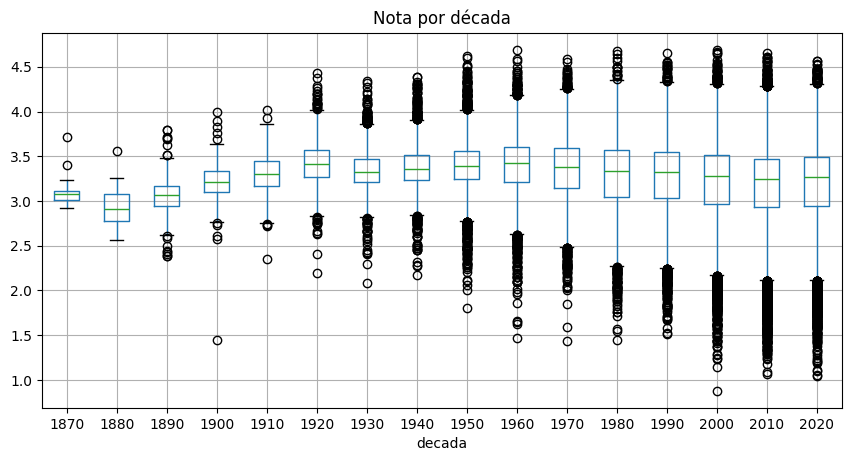

            date    rating
date    1.000000 -0.133438
rating -0.133438  1.000000


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = movies.copy()
# df já filtrado pelo mínimo de avaliações e sem nota nula
df = df.dropna(subset=["date", "rating"]).copy()
df["decada"] = (df["date"] // 10 * 10).astype(int)

top10 = df["rating"].quantile(0.90)
bot10 = df["rating"].quantile(0.10)

resumo = df.groupby("decada")["rating"].agg(
    n="count", media="mean", mediana="median", desvio="std",
    p90=lambda s: s.quantile(0.90),
)
resumo["%top10"] = df.groupby("decada")["rating"].apply(lambda s: (s >= top10).mean() * 100)
resumo["%bottom10"] = df.groupby("decada")["rating"].apply(lambda s: (s <= bot10).mean() * 100)
print(resumo.round(2))

df.boxplot(column="rating", by="decada", figsize=(10, 5))
plt.suptitle("")
plt.title("Nota por década")
plt.show()

# correlação monotônica (não assume relação linear)
print(df[["date", "rating"]].corr(method="spearman"))

In [13]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split

# movies e genres já foram carregados na primeira célula (download seletivo, sem posters)

print(movies.columns.tolist()); print(genres.columns.tolist())
print(genres.head())

# 1) Base com nota e ano
df = movies.dropna(subset=["rating", "date"]).copy()
df["date"] = df["date"].astype(int)
df = df[df["date"] <= 2026]
print("filmes com nota e ano:", len(df))

# 2) Alvo em 3 classes por percentil (20% / 60% / 20%)
q20, q80 = df["rating"].quantile([0.20, 0.80])
print(f"cortes: ruim <= {q20:.2f} | bom >= {q80:.2f}")
df["classe"] = np.select(
    [df["rating"] <= q20, df["rating"] >= q80],
    ["ruim", "bom"], default="mediocre")
print(df["classe"].value_counts(normalize=True).round(3))

# 3) Split ANTES de qualquer imputação, escala ou seleção
treino, teste = train_test_split(
    df, test_size=0.2, stratify=df["classe"], random_state=42)
print(len(treino), len(teste))

['id', 'name', 'date', 'tagline', 'description', 'minute', 'rating']
['id', 'genre']
        id      genre
0  1000001     Comedy
1  1000001  Adventure
2  1000002     Comedy
3  1000002   Thriller
4  1000002      Drama
filmes com nota e ano: 90999
cortes: ruim <= 2.93 | bom >= 3.56
classe
mediocre    0.590
bom         0.206
ruim        0.204
Name: proportion, dtype: float64
72799 18200


In [14]:
# Numéricas
print(treino.groupby("classe")[["minute", "date", "rating"]].agg(["mean", "median"]).round(2))

# Gêneros: proporção de filmes de cada classe que têm cada gênero
# (ajuste os nomes das colunas de genres.csv conforme o head())
g = genres.merge(treino[["id", "classe"]], on="id")
tabela = pd.crosstab(g["genre"], g["classe"], normalize="columns") * 100
tabela["dif_bom_ruim"] = tabela["bom"] - tabela["ruim"]
print(tabela.sort_values("dif_bom_ruim").round(1))

          minute            date         rating       
            mean median     mean  median   mean median
classe                                                
bom       122.36   98.0  1996.90  2005.0   3.75    3.7
mediocre   94.10   93.0  1997.05  2009.0   3.28    3.3
ruim       94.43   93.0  2007.20  2014.0   2.62    2.7
classe            bom  mediocre  ruim  dif_bom_ruim
genre                                              
Horror            1.8       4.7  13.4         -11.5
Thriller          3.6       6.3  10.8          -7.2
Action            3.1       5.3   9.1          -6.0
Comedy           12.5      15.7  16.2          -3.7
Science Fiction   2.0       2.4   5.4          -3.5
Adventure         2.5       3.0   4.7          -2.2
Family            2.2       3.1   4.3          -2.0
TV Movie          1.4       2.0   2.8          -1.4
Fantasy           2.7       2.7   3.5          -0.8
Romance           5.6       7.2   6.4          -0.8
Mystery           2.5       2.9   3.0         

In [7]:
#pergunta inversa
g = genres.merge(treino[["id", "classe"]], on="id")
p = pd.crosstab(g["genre"], g["classe"], normalize="index") * 100
p["n"] = g["genre"].value_counts()
print(p.sort_values("ruim", ascending=False).round(1))

classe            bom  mediocre  ruim      n
genre                                       
Horror            5.6      44.5  49.9   9043
Science Fiction  12.2      46.8  41.0   4445
Thriller          9.9      53.5  36.6   9945
Action           10.0      53.7  36.3   8422
Adventure        14.3      52.7  33.0   4792
TV Movie         12.7      56.5  30.8   3038
Family           13.1      56.3  30.6   4693
Fantasy          17.6      54.4  28.0   4268
Comedy           15.6      59.9  24.6  22259
Mystery          16.5      59.0  24.5   4177
Romance          15.7      62.3  22.0   9785
Crime            19.1      62.4  18.5   6853
Drama            23.6      64.1  12.3  31016
Western          16.8      71.0  12.3    971
Animation        27.0      61.7  11.2   6927
War              26.7      63.4   9.9   1636
Music            38.3      52.1   9.6   3249
History          28.0      64.9   7.2   2285
Documentary      42.6      54.6   2.8   8595


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer

# Gêneros em colunas 0/1 (sem aprender nada dos dados, então pode ser antes do split)
gen = pd.crosstab(genres["id"], genres["genre"]).clip(upper=1)
gen.columns = ["g_" + c for c in gen.columns]
df2 = df.merge(gen, left_on="id", right_index=True, how="left")
gcols = [c for c in df2.columns if c.startswith("g_")]
df2[gcols] = df2[gcols].fillna(0)

X = df2[["minute", "date"] + gcols]      # rating e classe ficam FORA dos atributos
y = df2["classe"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

pre = ColumnTransformer([
    ("minute", Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("log", FunctionTransformer(np.log1p)),
                         ("sc", StandardScaler())]), ["minute"]),
    ("ano", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), ["date"]),
    ("gen", "passthrough", gcols),
])
print(X_tr.shape, X_te.shape, y_tr.value_counts(normalize=True).round(3).to_dict())

(72799, 21) (18200, 21) {'mediocre': 0.59, 'bom': 0.206, 'ruim': 0.204}


In [9]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, cohen_kappa_score

# Alvo ordinal (a ordem importa para o kappa)
ordem = {"ruim": 0, "mediocre": 1, "bom": 2}
y_tr_o = y_tr.map(ordem); y_te_o = y_te.map(ordem)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "f1_macro": "f1_macro",
    "bal_acc": "balanced_accuracy",
    "kappa_q": make_scorer(cohen_kappa_score, weights="quadratic"),
}

modelos = {
    "logistica": (
        Pipeline([("pre", pre),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))]),
        {"clf__C": [0.1, 1, 10]},
    ),
    "floresta": (
        Pipeline([("pre", pre),
                  ("clf", RandomForestClassifier(class_weight="balanced",
                                                 n_estimators=200, n_jobs=-1,
                                                 random_state=42))]),
        {"clf__max_depth": [8, 16, None], "clf__min_samples_leaf": [5, 20]},
    ),
}

melhores = {}
for nome, (pipe, grade) in modelos.items():
    gs = GridSearchCV(pipe, grade, scoring="f1_macro", cv=cv, n_jobs=-1)
    gs.fit(X_tr, y_tr_o)
    melhores[nome] = gs.best_estimator_
    print(f"\n{nome}: melhores parâmetros {gs.best_params_}")

    # Mede o modelo escolhido com as 3 métricas, também por validação cruzada
    r = cross_validate(gs.best_estimator_, X_tr, y_tr_o, cv=cv, scoring=scoring)
    for m in scoring:
        v = r[f"test_{m}"]
        print(f"  {m}: {v.mean():.3f} ± {v.std():.3f}")


logistica: melhores parâmetros {'clf__C': 1}
  f1_macro: 0.479 ± 0.002
  bal_acc: 0.563 ± 0.002
  kappa_q: 0.413 ± 0.003

floresta: melhores parâmetros {'clf__max_depth': None, 'clf__min_samples_leaf': 5}
  f1_macro: 0.554 ± 0.002
  bal_acc: 0.622 ± 0.002
  kappa_q: 0.497 ± 0.003


In [15]:
# Estrutura dos arquivos extras
for a in ["themes.csv", "countries.csv", "languages.csv", "studios.csv", "actors.csv"]:
    d = pd.read_csv(caminhos[a], nrows=3)
    print(a, d.columns.tolist())
    print(d.head(3), "\n")

themes.csv ['id', 'theme']
        id                             theme
0  1000001  Humanity and the world around us
1  1000001            Crude humor and satire
2  1000001       Moving relationship stories 

countries.csv ['id', 'country']
        id      country
0  1000001           UK
1  1000001          USA
2  1000002  South Korea 

languages.csv ['id', 'type', 'language']
        id              type language
0  1000001          Language  English
1  1000002  Primary language   Korean
2  1000002   Spoken language  English 

studios.csv ['id', 'studio']
        id                   studio
0  1000001  LuckyChap Entertainment
1  1000001             Heyday Films
2  1000001           NB/GG Pictures 

actors.csv ['id', 'name', 'role']
        id             name    role
0  1000001    Margot Robbie  Barbie
1  1000001     Ryan Gosling     Ken
2  1000001  America Ferrera  Gloria 



In [16]:
def ler(arq):
    return pd.read_csv(caminhos[arq])

def escolher_coluna(d, preferidas):
    """Coluna com o valor (tema, país...). Tenta os nomes esperados; senão a de texto com mais valores distintos."""
    for p in preferidas:
        if p in d.columns:
            return p
    cand = [c for c in d.columns if c != "id" and d[c].dtype == object]
    return max(cand, key=lambda c: d[c].nunique())

def multi_hot(arq, preferidas, top, prefixo):
    d = ler(arq)
    col = escolher_coluna(d, preferidas)
    d = d.dropna(subset=[col]).drop_duplicates(["id", col])
    topn = d[col].value_counts().head(top).index      # só frequência, sem olhar o alvo
    d = d[d[col].isin(topn)]
    m = pd.crosstab(d["id"], d[col]).clip(upper=1)
    m.columns = [f"{prefixo}_{c}" for c in m.columns]
    print(f"{arq}: coluna usada = '{col}', {m.shape[1]} colunas 0/1")
    return m

def contagem(arq, nome):
    return ler(arq).groupby("id").size().rename(nome)

extras = [
    multi_hot("themes.csv",    ["theme"],    top=40, prefixo="tema"),
    multi_hot("countries.csv", ["country"],  top=15, prefixo="pais"),
    multi_hot("languages.csv", ["language"], top=15, prefixo="idioma"),
    multi_hot("studios.csv",   ["studio"],   top=30, prefixo="estudio"),
    multi_hot("actors.csv",    ["name"],     top=200, prefixo="ator"),
    contagem("countries.csv", "n_paises"),
    contagem("languages.csv", "n_idiomas"),
    contagem("actors.csv",    "n_atores"),
]

df3 = df2.drop_duplicates("id").set_index("id", drop=False)
df3 = df3.join(extras, how="left").reset_index(drop=True)

bin_cols = [c for c in df3.columns if c.startswith(("g_", "tema_", "pais_", "idioma_", "estudio_", "ator_"))]
cnt_cols = ["n_paises", "n_idiomas", "n_atores"]
df3[bin_cols] = df3[bin_cols].fillna(0)
df3[cnt_cols] = df3[cnt_cols].fillna(0)   # 0 = sem registro (não necessariamente "sem elenco")

# texto: sinopse + tagline (faltantes viram vazio)
df3["texto"] = (df3["description"].fillna("") + " " + df3["tagline"].fillna("")).str.strip()

print(df3.shape, "| filmes com texto:", (df3["texto"] != "").mean().round(3))

themes.csv: coluna usada = 'theme', 40 colunas 0/1
countries.csv: coluna usada = 'country', 15 colunas 0/1
languages.csv: coluna usada = 'language', 15 colunas 0/1
studios.csv: coluna usada = 'studio', 30 colunas 0/1
actors.csv: coluna usada = 'name', 200 colunas 0/1
(90999, 331) | filmes com texto: 0.994


/tmp/ipykernel_653/1949844743.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df3["texto"] = (df3["description"].fillna("") + " " + df3["tagline"].fillna("")).str.strip()


In [ ]:
#Ablação por blocos A e D
#Mesmo modelo, mesma validação cruzada, só no treino.
#Se o elenco (C) não melhora em relação a B,
#ele acrescenta pouco depois de conhecer o resto.
#Se a sinopse (D) não melhora, o texto não acrescenta nada.

from sklearn.feature_extraction.text import TfidfVectorizer

N_TREES = 100        # suba para 200 se o tempo permitir
MAX_TFIDF = 2000     # termos do TF-IDF

ordem = {"ruim": 0, "mediocre": 1, "bom": 2}
y4 = df3["classe"].map(ordem)
tr_idx, te_idx = train_test_split(df3.index, test_size=0.2, stratify=y4, random_state=42)

grupos = {
    "gen":    dict(bin=[c for c in bin_cols if c.startswith("g_")],  cnt=[]),
    "ctx":    dict(bin=[c for c in bin_cols if c.startswith(("tema_", "pais_", "idioma_", "estudio_"))],
                   cnt=["n_paises", "n_idiomas"]),
    "elenco": dict(bin=[c for c in bin_cols if c.startswith("ator_")], cnt=["n_atores"]),
}

def montar(blocos, usar_texto, clf):
    cnt = ["minute"] + sum((grupos[b]["cnt"] for b in blocos), [])
    binar = sum((grupos[b]["bin"] for b in blocos), [])
    etapas = [
        ("cnt", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p)),
                          ("sc", StandardScaler())]), cnt),
        ("ano", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), ["date"]),
        ("bin", "passthrough", binar),
    ]
    if usar_texto:
        etapas.append(("txt", TfidfVectorizer(max_features=MAX_TFIDF, min_df=5,
                                              stop_words="english", ngram_range=(1, 2)), "texto"))
    colunas = ["date"] + cnt + binar + (["texto"] if usar_texto else [])
    return Pipeline([("pre", ColumnTransformer(etapas)), ("clf", clf)]), colunas

def rf():
    return RandomForestClassifier(class_weight="balanced", n_estimators=N_TREES,
                                  min_samples_leaf=5, n_jobs=-1, random_state=42)

versoes = {
    "A: básico":     (["gen"], False),
    "B: + contexto": (["gen", "ctx"], False),
    "C: + elenco":   (["gen", "ctx", "elenco"], False),
    "D: + sinopse":  (["gen", "ctx", "elenco"], True),
}

linhas = []
for nome, (blocos, txt) in versoes.items():
    pipe, colunas = montar(blocos, txt, rf())
    r = cross_validate(pipe, df3.loc[tr_idx, colunas], y4[tr_idx], cv=cv,
                       scoring={"f1_macro": "f1_macro",
                                "kappa_q": make_scorer(cohen_kappa_score, weights="quadratic")})
    linhas.append({"versão": nome, "n_atributos": len(colunas) - 1,
                   "F1 macro": r["test_f1_macro"].mean(), "± F1": r["test_f1_macro"].std(),
                   "kappa quad.": r["test_kappa_q"].mean()})
    print(nome, "F1 macro: %.3f ± %.3f" % (r["test_f1_macro"].mean(), r["test_f1_macro"].std()))

res_ablacao = pd.DataFrame(linhas).set_index("versão").round(3)
res_ablacao

A: básico F1 macro: 0.554 ± 0.003
B: + contexto F1 macro: 0.601 ± 0.004
C: + elenco F1 macro: 0.592 ± 0.003


In [ ]:
#Leitura de texto: quais palavras puxam para "ruim" e para "bom"

txt_pipe = Pipeline([
    ("tf", TfidfVectorizer(max_features=5000, min_df=5, stop_words="english")),
    ("lr", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
txt_pipe.fit(df3.loc[tr_idx, "texto"], y4[tr_idx])

termos = np.array(txt_pipe.named_steps["tf"].get_feature_names_out())
coef = txt_pipe.named_steps["lr"].coef_          # linhas: 0=ruim, 1=mediocre, 2=bom
for i, nome in enumerate(["ruim", "mediocre", "bom"]):
    print(f"\n{nome}:", ", ".join(termos[np.argsort(coef[i])[::-1][:15]]))

f1_txt = cross_validate(txt_pipe, df3.loc[tr_idx, "texto"], y4[tr_idx], cv=cv, scoring="f1_macro")["test_score"]
print("\nF1 macro só com texto: %.3f ± %.3f" % (f1_txt.mean(), f1_txt.std()))